In [21]:
import torch
import torch.distributions as dist
import torch.nn as nn
from typing import List
from tqdm import tqdm

from utils import load_mnist_dataset, flatten_image, unflatten_image, view_image
from unet import get_timestep_embedding

In [2]:
#load_mnist_dataset()
trainY, testY = load_mnist_dataset()

In [3]:
len(trainY)

60000

In [4]:
trainY[0].shape

torch.Size([784])

In [5]:
28*28

784

In [6]:
def sample_multivariate_gaussian(mean, covariance, num_samples=1):
    """
    Function to sample from an N-dimensional multivariate Gaussian distribution
    :param mean:
    :param covariance:
    :param num_samples:
    :return:
    """
    # Create a multivariate normal distribution
    mvn = dist.MultivariateNormal(mean, covariance)
    # Sample from the distribution
    samples = mvn.sample((num_samples,))
    return samples

def unflatten_data(vector, shape=(28, 28)):
    """
    Function to unflatten an image
    :param vector: Flattened image tensor
    :param shape: Target shape
    :return: Unflattened image tensor
    """
    return vector.view(-1, 1, *shape)

def sample_batch(trainY, batch_size, device):
    indices = torch.randperm(len(trainY))[:batch_size]
    data = torch.stack([trainY[i] for i in indices]).to(device)
    data = unflatten_data(data)  # Reshape to (batch_size, 1, 28, 28)
    return torch.nn.functional.interpolate(data, size=(32, 32))

In [7]:
mean = torch.tensor([0.0, 0.0])  # Example mean for a 2D Gaussian
covariance_matrix = torch.tensor([[1.0, 0.5], [0.5, 1.0]])  # Example covariance matrix


In [8]:
sample_multivariate_gaussian(mean=mean, covariance=covariance_matrix, num_samples=2)

tensor([[-2.7550, -3.7950],
        [ 1.0796, -1.1362]])

In [9]:
t_sample = torch.rand(10,device='cuda', dtype=torch.float32)
t_sample.shape
t_sample = t_sample.unsqueeze(1).unsqueeze(2).unsqueeze(3)  # Shape: (10, 1, 1, 1)

In [10]:
test_sample_y = sample_batch(trainY, batch_size=10, device='cuda')

In [16]:
x_sample = torch.randn(test_sample_y.shape, device='cuda')
x_sample.shape

torch.Size([10, 1, 32, 32])

In [12]:
prod = torch.randn(test_sample_y.shape, device='cuda')*t_sample
prod.shape

torch.Size([10, 1, 32, 32])

In [13]:
test_sample_y.shape

torch.Size([10, 1, 32, 32])

In [14]:
test_sample_y[0][0][23]

tensor([-1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
        -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,  0.4196,
         0.9765,  0.9765,  0.9843,  0.4824, -0.7647, -1.0000, -1.0000, -1.0000,
        -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000],
       device='cuda:0')

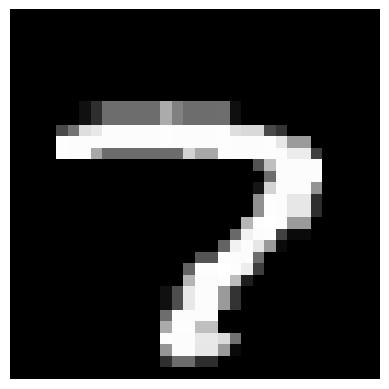

In [15]:
view_image(test_sample_y.cpu()[0])

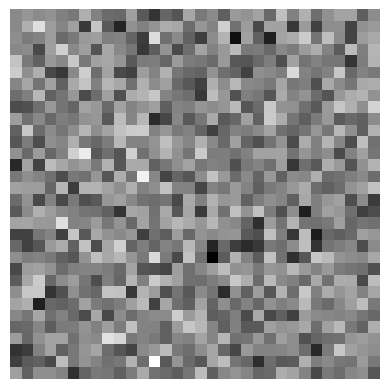

In [17]:
view_image(x_sample.cpu()[0])

In [18]:
get_timestep_embedding(torch.tensor([0.4]), embedding_dim=12)

tensor([[3.8942e-01, 6.3353e-02, 1.0047e-02, 1.5924e-03, 2.5238e-04, 4.0000e-05,
         9.2106e-01, 9.9799e-01, 9.9995e-01, 1.0000e+00, 1.0000e+00, 1.0000e+00]])

In [22]:
class SimpleBrownianBridgeDiffusion:

    def __init__(self, T: float, model: nn.Module, device: str, trainY: List):
        self.T = T
        self.function_approximator = model.to(device)
        self.device = device
        self.trainY = trainY


    def train(self, batch_size, optimizer):
        """
        Corollary 2.7 implementation
        """

        # sample target images y
        y = sample_batch(self.trainY, batch_size, self.device)
        # sample random times from [0,T)
        t = torch.rand(batch_size,device=self.device, dtype=torch.float32)*self.T
        # Unsqueeze t to align dimensions
        t = t.unsqueeze(1).unsqueeze(2).unsqueeze(3)  # Shape: (batch_size, 1, 1, 1)
        # sample x as independent gaussians 
        x = torch.randn(y.shape, device=self.device)
        # compute E_t
        E = x + (y-x)*t/self.T
        # compute V_t
        V = t*(T-t)/T
        # compute xi_t sampling 
        xi = torch.randn(y.shape, device=self.device) + x*torch.sqrt(V)
        # Take one gradient descent step
        # The input to function_approximator must be 4D: (batch_size, channels, height, width)
        img_predicted = self.function_approximator(xi, t)
        loss = nn.functional.mse_loss(y, img_predicted)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        return loss.item()